# Next-Word Prediction with an LSTM (FAQ Chatbot-style Text Generator)

**What this notebook does:** it learns from a small set of FAQs and then, given a few starting words
(e.g. `what is the fee`), predicts the *next* word, one word at a time.

**Pipeline**
1. Define the FAQ text (new FAQs: a *Python Programming Bootcamp*)
2. Tokenize: words -> integer ids
3. Build training sequences: `[w1, w2]`, `[w1, w2, w3]`, ...
4. Pad sequences to equal length
5. Split into **X** (all words except the last) and **y** (the last word = the target)
6. Build and train an **Embedding -> LSTM -> LSTM -> Dense(softmax)** model
7. Generate text with the trained model

**Fixes compared to the original notebook**
- Added `return_sequences=True` on the first LSTM (the original crashed with *expected ndim=3, found ndim=2*)
- Added the missing `import numpy as np`
- Removed deprecated `input_length`
- `vocab_size` and `max_len` are computed automatically instead of hardcoded (283 / 56)
- Faster word lookup using a reverse dictionary

## 1. Imports

In [1]:
import time                      # used only to make the generated text appear word by word
import numpy as np               # needed for np.argmax when predicting (missing in the original)
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer          # text -> integer ids
from tensorflow.keras.preprocessing.sequence import pad_sequences  # make all sequences equal length
from tensorflow.keras.utils import to_categorical                  # integer -> one-hot vector
from tensorflow.keras.models import Sequential                     # simple stack of layers
from tensorflow.keras.layers import Embedding, LSTM, Dense

print("TensorFlow version:", tf.__version__)

I0000 00:00:1794898213.099375     144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794898213.154074     144 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794898214.527379     144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


## 2. The FAQ text (changed)
Each line is either a section heading, a question, or an answer. We train on every line, so the model learns the
style and vocabulary of the FAQs.

In [2]:
faqs = """About the Bootcamp
What is the course fee for the Python Programming Bootcamp
The course follows a monthly subscription model where you have to pay Rs 999 per month.
What is the total duration of the course?
The total duration of the course is 6 months so the total course fee becomes Rs 5994 approximately.
What is the syllabus of the bootcamp?
We will be covering the following modules:
Python Basics
Object Oriented Programming
Data Structures and Algorithms
Web Development with Flask
Databases and SQL
Testing and Deployment
Capstone Projects
Will machine learning be a part of this bootcamp?
No, machine learning is not a part of this bootcamp curriculum.
What if I miss a live class? Will I get a recording of the class?
Yes, all our classes are recorded so even if you miss a class you can watch the recording later.
Where can I find the class schedule?
You can find the month by month class schedule in your dashboard after you make the payment.
What is the time duration of all the live classes?
Roughly, all the classes last 2 hours.
What is the language spoken by the instructor during the classes?
The instructor teaches in English.
How will I be informed about the upcoming class?
You will get an email from our side before every class once you become a paid student.
Can I do this course if I am from a non tech background?
Yes, absolutely. The course starts from the very basics.
I am late, can I join the bootcamp in the middle?
Absolutely, you can join the bootcamp at any time.
If I join in the middle, will I be able to see all the past classes?
Yes, once you make the payment you will be able to see all the past classes in your dashboard.
Where do I have to submit the assignment?
You can submit the assignment on the website and our team will review it within 3 days.
Will we build projects in the bootcamp?
Yes, you will build many projects and one big capstone project.
Where can we contact you?
You can mail us at support@pythonbootcamp.example
Payment and Registration
Where do we have to make our payments?
You have to make all your monthly payments on our website.
Can we pay the entire amount of Rs 5994 all at once?
Unfortunately no, the bootcamp follows a monthly subscription model.
What is the validity of the monthly subscription?
The validity period is 30 days from the day you make the payment so you can join at any time.
What if I do not like the course after making the payment? What is the refund policy?
You get a 7 days refund period from the day you have made the payment.
I am living outside India and I am not able to make the payment on the website, what should I do?
You have to contact us by sending an email to support@pythonbootcamp.example
Certificate and Placement Assistance
What is the criteria to get the certificate?
There are 2 criteria:
You have to pay the entire fee of Rs 5994
You have to submit all the assignments and the capstone project
I am joining late. How can I pay the payment of the earlier months?
You will get a link to pay the fee of the earlier months in your dashboard once you pay for the current month.
Does the bootcamp provide placement assistance?
Placement assistance does not mean placement guarantee. We do not guarantee any job or interview call.
Here is what comes under placement assistance:
Resume building sessions
Mock interview sessions
Sessions with industry mentors
Discussion on job hunting strategies
"""

## 3. Tokenization
The `Tokenizer` builds a vocabulary (word -> unique integer id) from the text. Ids start from **1**; id **0** is
reserved for padding. It also lowercases everything and strips punctuation.

In [3]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([faqs])          # learn the vocabulary from the FAQ text

# +1 because id 0 is reserved for padding, so valid ids are 0 .. len(word_index)
vocab_size = len(tokenizer.word_index) + 1
print("Unique words :", len(tokenizer.word_index))
print("Vocab size   :", vocab_size)

# A peek at the first 10 vocabulary entries (most frequent words get the smallest ids)
print(dict(list(tokenizer.word_index.items())[:10]))

Unique words : 201
Vocab size   : 202
{'the': 1, 'you': 2, 'i': 3, 'to': 4, 'what': 5, 'is': 6, 'of': 7, 'can': 8, 'a': 9, 'will': 10}


## 4. Create n-gram training sequences
For every line we create growing prefixes. Example for the line `what is the fee`:

| Sequence | Input (X) | Target (y) |
|---|---|---|
| `what is` | `what` | `is` |
| `what is the` | `what is` | `the` |
| `what is the fee` | `what is the` | `fee` |

We do this **per line** (not on the whole text) so that a sequence never mixes the end of one line with the start of
the next.

In [4]:
input_sequences = []

for sentence in faqs.split('\n'):
    if not sentence.strip():                 # skip empty lines
        continue

    # words -> ids, e.g. "what is the fee" -> [11, 7, 1, 52]
    tokenized_sentence = tokenizer.texts_to_sequences([sentence])[0]

    # build prefixes of length 2, 3, ... len(sentence)
    for i in range(1, len(tokenized_sentence)):
        input_sequences.append(tokenized_sentence[:i + 1])

print("Total training sequences:", len(input_sequences))
print("First 5 sequences       :", input_sequences[:5])

Total training sequences: 552
First 5 sequences       : [[62, 1], [62, 1, 11], [5, 6], [5, 6, 1], [5, 6, 1, 13]]


## 5. Padding
Neural networks need inputs of the **same length**. We find the longest sequence and left-pad (`padding='pre'`) the
rest with zeros. Padding on the *left* keeps the most recent words right next to the output, which is what an LSTM
works best with.

In [5]:
max_len = max(len(seq) for seq in input_sequences)   # computed automatically (original hardcoded 56)
print("Longest sequence:", max_len)

padded_input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding='pre')
print("Padded shape    :", padded_input_sequences.shape)
print(padded_input_sequences[:3])

Longest sequence: 23
Padded shape    : (552, 23)
[[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 62  1]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 62  1 11]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  5  6]]


## 6. Split into X and y
- **X** = every word except the last one (the context)
- **y** = the last word (what we want the model to predict)

Then `y` is **one-hot encoded** because we use `categorical_crossentropy` with a softmax output over the whole
vocabulary.

In [6]:
X = padded_input_sequences[:, :-1]    # context words      -> shape (num_samples, max_len - 1)
y = padded_input_sequences[:, -1]     # word to predict    -> shape (num_samples,)

y = to_categorical(y, num_classes=vocab_size)   # -> shape (num_samples, vocab_size)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (552, 22)
y shape: (552, 202)


## 7. Build the model
| Layer | What it does |
|---|---|
| `Embedding` | Turns each word id into a dense 100-dim vector that captures word meaning |
| `LSTM(150, return_sequences=True)` | Reads the sequence and outputs the hidden state at **every** time step (needed so the next LSTM receives 3D input) |
| `LSTM(150)` | Reads those outputs and returns only the **final** hidden state (a summary of the whole sentence) |
| `Dense(vocab_size, softmax)` | Gives a probability for every word in the vocabulary being the next word |

> **The bug fix:** the original code stacked two `LSTM` layers without `return_sequences=True`, so the second LSTM
> received 2D data and crashed.

In [7]:
model = Sequential([
    tf.keras.Input(shape=(max_len - 1,)),                  # input: sequence of word ids (replaces deprecated input_length)
    Embedding(input_dim=vocab_size, output_dim=100),       # word id -> 100-dim vector
    LSTM(150, return_sequences=True),                      # keep output at every time step (3D) for the next LSTM
    LSTM(150),                                             # only the final output (2D) goes to Dense
    Dense(vocab_size, activation='softmax')                # probability of each word being next
])

model.compile(
    loss='categorical_crossentropy',   # multi-class loss with one-hot targets
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 22, 100)        │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 22, 150)        │       150,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 150)            │       180,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 202)            │        30,502 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,902 (1.46 MB)

 Trainable params: 381,902 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train
The dataset is tiny, so we *want* the model to memorise the FAQ phrasing (the goal here is a demo, not
generalisation). ~100 epochs usually gives high accuracy. Change `EPOCHS` if you want it faster or better.

In [8]:
EPOCHS = 100

history = model.fit(X, y, epochs=EPOCHS, batch_size=64, verbose=0)

# verbose=0 keeps the output clean; print progress every 10 epochs instead
for epoch in range(9, EPOCHS, 10):
    print(f"Epoch {epoch + 1:3d}/{EPOCHS} - loss: {history.history['loss'][epoch]:.4f} "
          f"- accuracy: {history.history['accuracy'][epoch]:.4f}")

Epoch  10/100 - loss: 4.6258 - accuracy: 0.1069
Epoch  20/100 - loss: 4.2634 - accuracy: 0.1232
Epoch  30/100 - loss: 3.7802 - accuracy: 0.1359
Epoch  40/100 - loss: 3.1047 - accuracy: 0.2681
Epoch  50/100 - loss: 2.4913 - accuracy: 0.4330
Epoch  60/100 - loss: 1.9773 - accuracy: 0.5562
Epoch  70/100 - loss: 1.5532 - accuracy: 0.6775
Epoch  80/100 - loss: 1.2043 - accuracy: 0.7681
Epoch  90/100 - loss: 0.9487 - accuracy: 0.8297
Epoch 100/100 - loss: 0.7537 - accuracy: 0.8659


## 9. Training curves (optional)

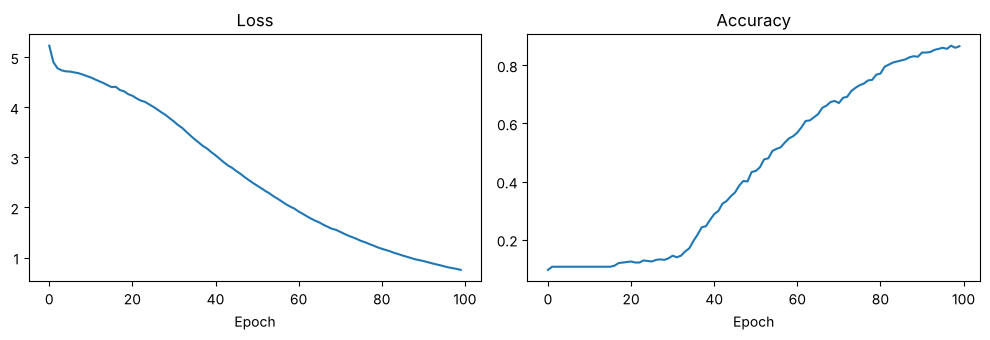

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history['loss']);     ax[0].set_title('Loss');     ax[0].set_xlabel('Epoch')
ax[1].plot(history.history['accuracy']); ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch')
plt.tight_layout()
plt.show()

## 10. Generate text
How it works, repeated for N words:
1. Tokenize the current text and left-pad it to `max_len - 1`
2. The model outputs probabilities for every word
3. `np.argmax` picks the most likely next word
4. Convert the id back to a word (using a reverse dictionary) and append it to the text

> **Improvement over the original:** the original looped over the whole vocabulary to find each word.
> A reverse dictionary (`index_word`) does it in one step.

In [10]:
# id -> word lookup, built once (Tokenizer already provides this as tokenizer.index_word)
index_to_word = tokenizer.index_word


def generate_text(seed_text, next_words=10, delay=0.0):
    """Predict `next_words` words one at a time, starting from `seed_text`."""
    text = seed_text

    for _ in range(next_words):
        # 1. tokenize: "what is the fee" -> [11, 7, 1, 52]
        token_text = tokenizer.texts_to_sequences([text])[0]

        # 2. pad to the exact input length the model expects (max_len - 1)
        padded_token_text = pad_sequences([token_text], maxlen=max_len - 1, padding='pre')

        # 3. predict probabilities for all words and pick the most likely one
        probs = model.predict(padded_token_text, verbose=0)
        pos = int(np.argmax(probs))

        # 4. convert id -> word; id 0 (padding) has no word, so stop if that happens
        word = index_to_word.get(pos)
        if word is None:
            break

        text += " " + word
        print(text)
        time.sleep(delay)      # set delay=1 or 2 to see it appear word by word

    return text


final_text = generate_text("what is the fee", next_words=10)

what is the fee of
what is the fee of the
what is the fee of the monthly
what is the fee of the monthly subscription


what is the fee of the monthly subscription model
what is the fee of the monthly subscription model where
what is the fee of the monthly subscription model where you
what is the fee of the monthly subscription model where you have


what is the fee of the monthly subscription model where you have to
what is the fee of the monthly subscription model where you have to pay


Try a few more starting phrases:

In [11]:
for seed in ["what is the", "can i join", "where can i", "will i get a"]:
    print("SEED:", seed)
    result = generate_text(seed, next_words=8)
    print("RESULT:", result)
    print("-" * 60)

SEED: what is the
what is the bootcamp
what is the bootcamp follows


what is the bootcamp follows a


what is the bootcamp follows a monthly
what is the bootcamp follows a monthly subscription
what is the bootcamp follows a monthly subscription model


what is the bootcamp follows a monthly subscription model where


what is the bootcamp follows a monthly subscription model where you
RESULT: what is the bootcamp follows a monthly subscription model where you
------------------------------------------------------------
SEED: can i join
can i join the
can i join the bootcamp


can i join the bootcamp at


... (7 outputs left out)

will i get a link to


will i get a link to pay
will i get a link to pay the
will i get a link to pay the fee


will i get a link to pay the fee of


will i get a link to pay the fee of the
will i get a link to pay the fee of the earlier
RESULT: will i get a link to pay the fee of the earlier
------------------------------------------------------------


## Notes
- **Why the output repeats or loops:** greedy `argmax` always picks the single most likely word, so generation is
  deterministic and can loop. For more varied text, sample from `probs` instead of taking `argmax`.
- **Why it only mimics the FAQs:** with so little data the model memorises phrases. More text = better language model.
- **Changing the FAQs:** just edit the `faqs` string in section 2. `vocab_size` and `max_len` update automatically.